# Interdot detector, step by step

`predict(image)` of `stage1_linefilter/detector.py` turns a raw charge-stability diagram
into a binary mask of its interdot transitions (the **sticks**). It is a classical pipeline —
no training, six parameters (`PARAMS`) — made of four operations:

1. remove the offset of each scan line;
2. find **seeds**: pixels that are significantly dark once averaged along the stick direction;
3. around the seeds, keep the pixels deeper than a fraction of their component's peak depth;
4. delete the components that do not run along the stick direction.

Each section below shows one operation: the image before, the image after, and why it is done.

## 0. Setup

The example is the stage-2 reference image of `new_experiment(seed=1007)` (0.3 V window, 2 mV
per pixel). `stages` recomputes every intermediate result of `predict` with the detector's own
functions and parameters, and checks that its last one is exactly `predict(image)`.

In [1]:
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
from scipy.ndimage import binary_dilation, correlate
from scipy.ndimage import label as ndlabel
from scipy.ndimage import maximum as ndmaximum
from skimage.measure import label, regionprops

ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "csd").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

from csd import new_experiment
from stage1_linefilter.detector import (
    N_ORIENT,
    PARAMS,
    filter_by_orientation,
    line_kernel,
    predict,
    robust_depth,
)
from stage1_linefilter.eval_detector import ensure_dataset, evaluate

plt.rcParams.update({"figure.dpi": 110, "image.origin": "lower", "axes.titlesize": 10})
STEP = 2e-3  # V per pixel
ZOOM = (slice(15, 55), slice(17, 57))  # rows (g4), cols (g2): around one stick

exp = new_experiment(seed=1007)
image = exp.measure(span_h=0.3, span_v=0.3, step_h=STEP, step_v=STEP)


def stages(image):
    "Every intermediate result of `predict(image)`, in order."
    p = PARAMS
    rows = image - np.median(image, axis=1, keepdims=True)
    depth = robust_depth(rows)
    along = robust_depth(correlate(rows, np.eye(p["line_len"]) / p["line_len"], mode="nearest"))
    seeds = along > p["k_line"]
    dilated = binary_dilation(seeds, iterations=p["dilate"])
    cand = dilated & (depth > p["k_low"])
    labels, n = ndlabel(cand, structure=np.ones((3, 3)))
    smooth = correlate(depth, np.eye(2) / 2, mode="nearest")
    amp = np.concatenate([[0.0], ndmaximum(smooth, labels, np.arange(1, n + 1))])[labels]
    fwhm = cand & (depth > p["half"] * amp) & (amp > p["k_peak"])
    final = filter_by_orientation(fwhm, rows)
    assert (final == predict(image)).all()
    return {
        "rows": rows, "depth": depth, "along": along, "seeds": seeds, "dilated": dilated,
        "cand": cand, "smooth": smooth, "amp": amp, "fwhm": fwhm, "final": final,
    }  # fmt: skip


def panel(ax, img, title, mask=None, color="tab:red", **kw):
    "Draw an image, with an optional mask painted over it."
    im = ax.imshow(img, **{"cmap": "gray", **kw})
    if mask is not None:
        ax.imshow(np.ma.masked_where(~mask, mask), cmap=ListedColormap([color]), alpha=0.65)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    return im


s = stages(image)

## 1. Raw image

Rows are $g_4$, columns are $g_2$. A **stick** is a short dark segment at 45°: the interdot
transition, where an electron moves from one dot to the other. It is a dip of a few pixels,
barely deeper than the noise. The horizontal stripes are the drift of the charge sensor from one
scan line to the next. The charge-transition lines of each dot, which end on the sticks, are
almost invisible in this image (one is visible in §6). The framed region is the zoom used in the
next sections.

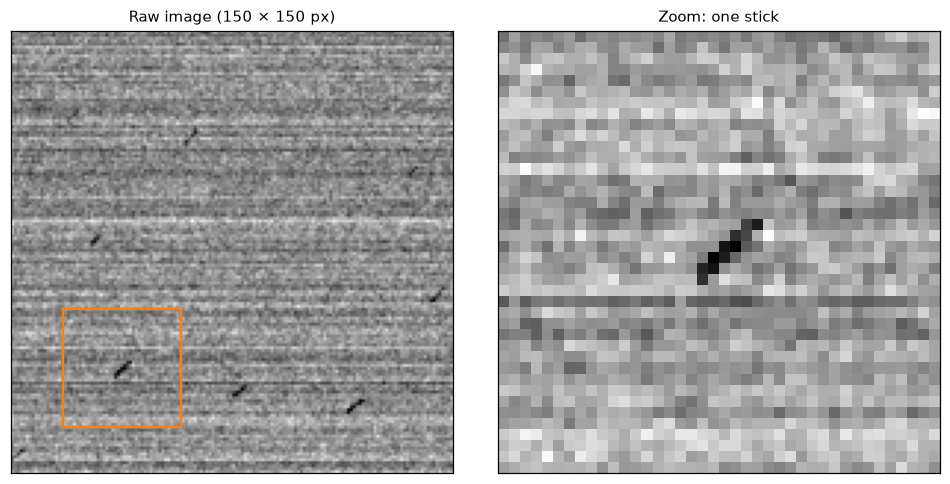

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
panel(axes[0], image, "Raw image (150 × 150 px)")
r, c = ZOOM
axes[0].add_patch(
    Rectangle(
        (c.start, r.start), c.stop - c.start, r.stop - r.start, fill=False, ec="tab:orange", lw=1.5
    )
)
panel(axes[1], image[ZOOM], "Zoom: one stick")
plt.tight_layout()

## 2. Per-row median removal

**Before:** every scan line carries its own offset, as large as the noise of a pixel.
**Operation:** subtract from each row its median. **After:** the stripes are gone. The median is
used rather than the mean because a stick covers a few pixels of a row only: it does not move
the median, so it is not attenuated.

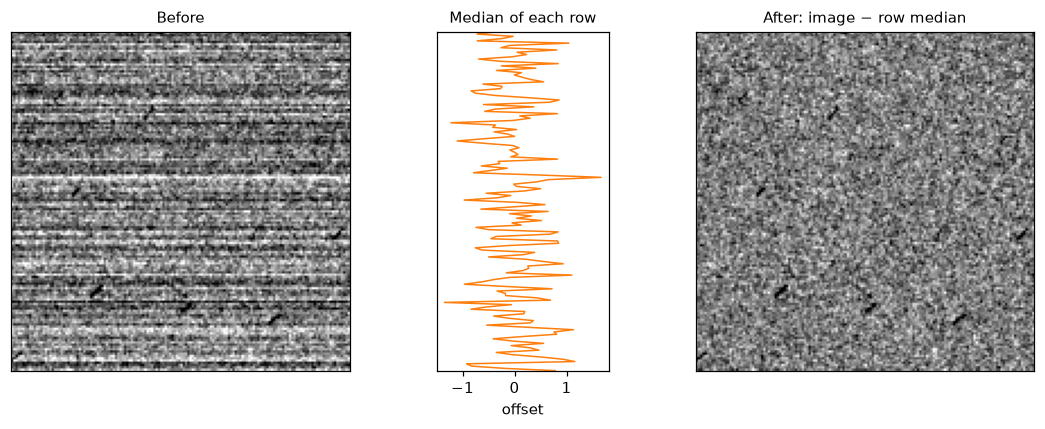

In [3]:
offset = np.median(image, axis=1)
lim = {"vmin": np.percentile(image, 1), "vmax": np.percentile(image, 99)}
fig, axes = plt.subplots(1, 3, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 0.35, 1]})
panel(axes[0], image, "Before", **lim)
axes[1].plot(offset, np.arange(len(offset)), color="tab:orange", lw=1)
axes[1].set(ylim=(0, len(offset) - 1), title="Median of each row", xlabel="offset")
axes[1].set_yticks([])
panel(
    axes[2],
    s["rows"],
    "After: image − row median",
    vmin=lim["vmin"] - offset.mean(),
    vmax=lim["vmax"] - offset.mean(),
)
plt.tight_layout()

## 3. Robust depth

**Operation:** express every pixel as a depth in noise units,
$d = (\mathrm{median} - a)\,/\,(1.4826 \cdot \mathrm{MAD})$, so that the thresholds do not depend
on the scale or noise level of the image. Median and MAD (median absolute deviation) measure the
background and its noise without being pulled by the sticks. **After:** the background follows a
unit Gaussian and the sticks are the positive tail — but a single pixel of a stick is only a few
σ deep, not enough to threshold it directly.

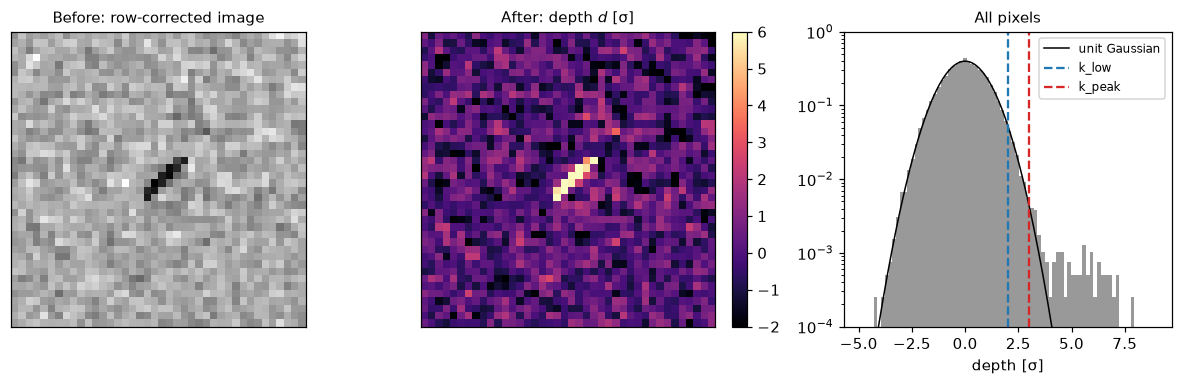

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
panel(axes[0], s["rows"][ZOOM], "Before: row-corrected image")
im = panel(axes[1], s["depth"][ZOOM], "After: depth $d$ [σ]", cmap="magma", vmin=-2, vmax=6)
plt.colorbar(im, ax=axes[1], fraction=0.046)
x = np.linspace(-5, 9, 200)
axes[2].hist(s["depth"].ravel(), bins=80, range=(-5, 9), density=True, color="0.6")
axes[2].plot(x, np.exp(-(x**2) / 2) / np.sqrt(2 * np.pi), color="k", lw=1, label="unit Gaussian")
axes[2].axvline(PARAMS["k_low"], color="tab:blue", ls="--", label="k_low")
axes[2].axvline(PARAMS["k_peak"], color="tab:red", ls="--", label="k_peak")
axes[2].set(yscale="log", ylim=(1e-4, 1), xlabel="depth [σ]", title="All pixels")
axes[2].legend(fontsize=8)
plt.tight_layout()

## 4. Matched filter, seeds and candidates

**Operation:** average the image over `line_len` = 5 pixels along the 45° diagonal, then take the
depth again. Along a stick the dip adds up while the noise averages out (÷ √5): the stick stands
out, lines in other directions do not.

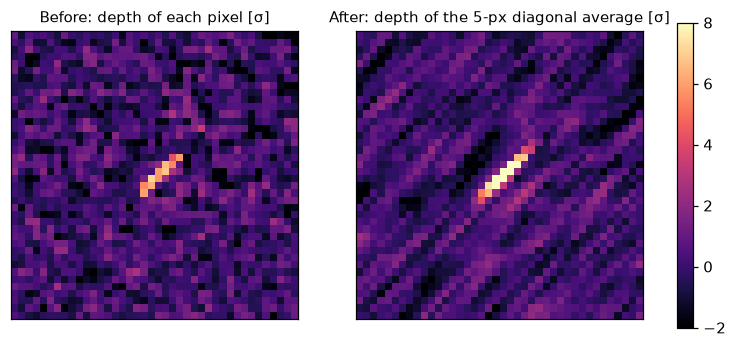

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
kw = {"cmap": "magma", "vmin": -2, "vmax": 8}
panel(axes[0], s["depth"][ZOOM], "Before: depth of each pixel [σ]", **kw)
im = panel(axes[1], s["along"][ZOOM], "After: depth of the 5-px diagonal average [σ]", **kw)
plt.colorbar(im, ax=axes, fraction=0.023)
plt.show()

The filtered depth says *where* a stick is, not its exact shape. So: **seeds** = filtered depth
> `k_line` (3.5 σ); the seeds are **dilated** by 2 px to cover the whole stick; inside that
region the **candidates** are the pixels whose own depth is > `k_low` (2 σ). A 2 σ threshold
alone would keep ~2 % of the background; restricted to the seeds' neighbourhood it is safe.

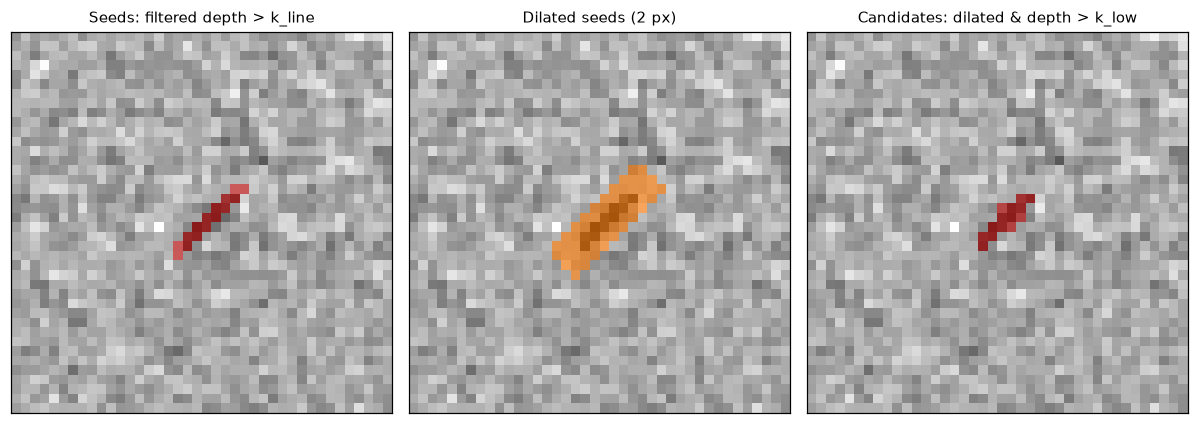

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
panel(axes[0], s["rows"][ZOOM], "Seeds: filtered depth > k_line", s["seeds"][ZOOM])
panel(axes[1], s["rows"][ZOOM], "Dilated seeds (2 px)", s["dilated"][ZOOM], "tab:orange")
panel(axes[2], s["rows"][ZOOM], "Candidates: dilated & depth > k_low", s["cand"][ZOOM])
plt.tight_layout()

## 5. Full width at half maximum, per component

**Before:** a candidate component is the stick plus shallower pixels around it: the tails of the
dip on its sides, the start of the charge lines at its ends. **Operation:** the
amplitude $A$ of a connected component is its largest depth (averaged over 2 px, a single pixel
is biased by the noise); keep the pixels with $d >$ `half` $\cdot A$ (0.6) and drop the whole
component if $A <$ `k_peak` (3 σ). **After:** the mask stops where the dip falls to about half
of its depth, whatever the contrast of the stick.

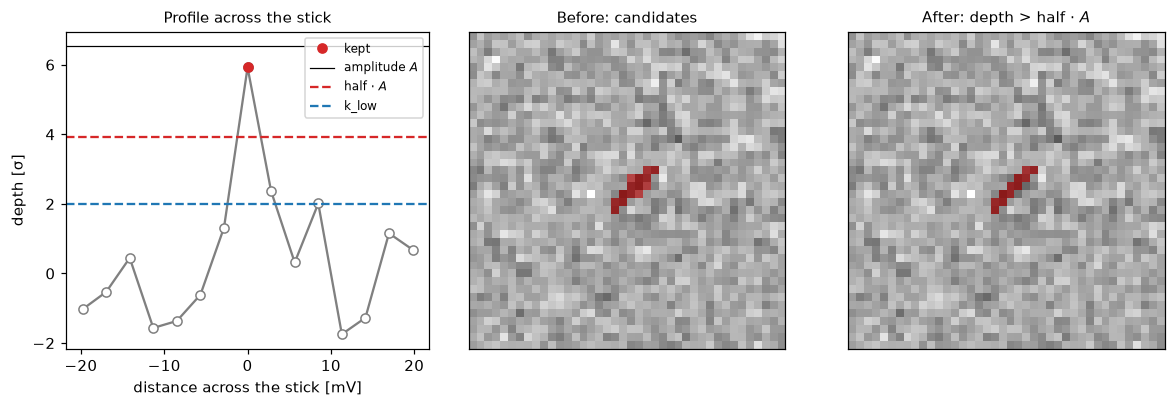

In [7]:
cand, depth = s["cand"][ZOOM], s["depth"][ZOOM]
r0, c0 = np.unravel_index(np.argmax(np.where(cand, s["smooth"][ZOOM], -np.inf)), cand.shape)
A = s["amp"][ZOOM][r0, c0]
t = np.arange(-7, 8)
kept = s["fwhm"][ZOOM][r0 - t, c0 + t]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
axes[0].plot(t * STEP * np.sqrt(2) * 1e3, depth[r0 - t, c0 + t], "o-", color="0.5", mfc="w")
axes[0].plot(
    t[kept] * STEP * np.sqrt(2) * 1e3,
    depth[r0 - t, c0 + t][kept],
    "o",
    color="tab:red",
    label="kept",
)
axes[0].axhline(A, color="k", lw=0.8, label="amplitude $A$")
axes[0].axhline(PARAMS["half"] * A, color="tab:red", ls="--", label="half · $A$")
axes[0].axhline(PARAMS["k_low"], color="tab:blue", ls="--", label="k_low")
axes[0].set(
    xlabel="distance across the stick [mV]", ylabel="depth [σ]", title="Profile across the stick"
)
axes[0].legend(fontsize=8)
panel(axes[1], s["rows"][ZOOM], "Before: candidates", cand)
panel(axes[2], s["rows"][ZOOM], "After: depth > half · $A$", s["fwhm"][ZOOM])
plt.tight_layout()

## 6. Orientation filter

**Before:** some components that pass the previous steps are fragments of a deep charge line,
not sticks. **Operation:** the image is averaged along 8 orientations (kernels below); a
component's direction is the orientation whose average is the darkest over its pixels. It is
kept if that direction is 45° ± one bin (22.5°), deleted otherwise. This works even for
components of a few pixels, whose shape says nothing about their direction.

The seed-1007 image has no such fragment, so this section uses an image of the stage-1
validation set (`data/val`, regenerated with `csd.generate_dataset(n=256, seed=2)`).

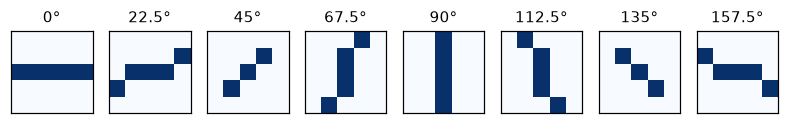

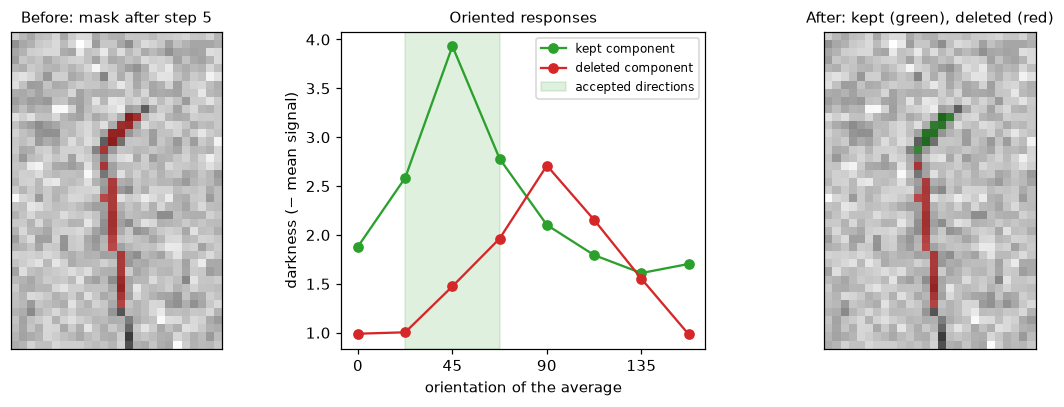

In [8]:
ds_image = np.load(ensure_dataset(ROOT / "data/val", n=256, seed=2) / "images.npy", mmap_mode="r")[
    10
].astype(float)
d = stages(ds_image)
angles = np.arange(N_ORIENT) * 180 / N_ORIENT
resp = np.array(
    [correlate(d["rows"], line_kernel(np.deg2rad(a), 2), mode="nearest") for a in angles]
)

fig, axes = plt.subplots(1, N_ORIENT, figsize=(9, 1.5))
for ax, a in zip(axes, angles):
    panel(ax, line_kernel(np.deg2rad(a), 2), f"{a:g}°", cmap="Blues")
plt.show()

regions = regionprops(label(d["fwhm"], connectivity=2))
is_kept = [d["final"][tuple(reg.coords[0])] for reg in regions]
bad = max((reg for reg, k in zip(regions, is_kept) if not k), key=lambda reg: reg.area)
good = min(
    (reg for reg, k in zip(regions, is_kept) if k),
    key=lambda reg: np.hypot(*np.subtract(reg.centroid, bad.centroid)),
)
lo = np.maximum(np.minimum(bad.centroid, good.centroid).astype(int) - 12, 0)
hi = np.maximum(bad.centroid, good.centroid).astype(int) + 13
crop = (slice(lo[0], hi[0]), slice(lo[1], hi[1]))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
panel(axes[0], d["rows"][crop], "Before: mask after step 5", d["fwhm"][crop])
for reg, color, name in ((good, "tab:green", "kept"), (bad, "tab:red", "deleted")):
    rr, cc = reg.coords.T
    axes[1].plot(
        angles, -resp[:, rr, cc].mean(axis=1), "o-", color=color, label=f"{name} component"
    )
axes[1].axvspan(22.5, 67.5, color="tab:green", alpha=0.15, label="accepted directions")
axes[1].set(
    xticks=angles[::2],
    xlabel="orientation of the average",
    ylabel="darkness (− mean signal)",
    title="Oriented responses",
)
axes[1].legend(fontsize=8)
panel(axes[2], d["rows"][crop], "After: kept (green), deleted (red)", d["final"][crop], "tab:green")
axes[2].imshow(
    np.ma.masked_where(d["final"] | ~d["fwhm"], d["fwhm"])[crop],
    cmap=ListedColormap(["tab:red"]),
    alpha=0.65,
)
plt.tight_layout()

## 7. Final mask and score

The mask of the seed-1007 image, and the Dice score ($2|P \cap T| / (|P| + |T|)$ between the
predicted and true masks) of each of the 256 images of the stage-1 validation set.

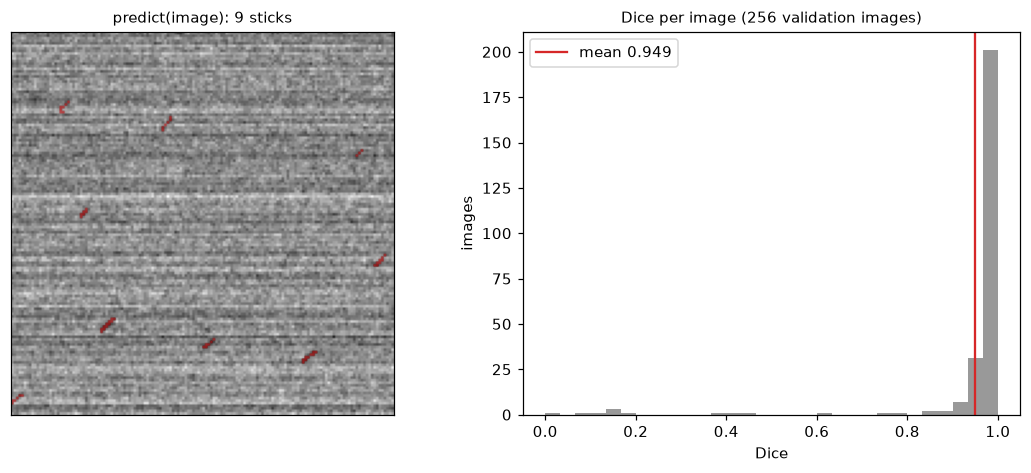

In [9]:
scores = evaluate(ensure_dataset(ROOT / "data/val", n=256, seed=2))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
panel(
    axes[0], image, f"predict(image): {label(s['final'], connectivity=2).max()} sticks", s["final"]
)
axes[1].hist(scores, bins=30, color="0.6")
axes[1].axvline(scores.mean(), color="tab:red", label=f"mean {scores.mean():.3f}")
axes[1].set(
    xlabel="Dice", ylabel="images", title=f"Dice per image ({len(scores)} validation images)"
)
axes[1].legend()
plt.tight_layout()

## 8. Results

The detector on 2000 fresh images drawn from the organisers' generator
(`csd.generate_dataset`, seed 2026 — a seed never used to tune the six parameters; the folder
`data/stage1_results` is generated on the first run). One Dice score per image, with its mean,
standard deviation, median and low tail.

Below the histogram, four images taken across the distribution rather than hand-picked — the
worst, the 5th percentile, the median and the best — each shown in line as the original image,
the predicted mask and the target mask.

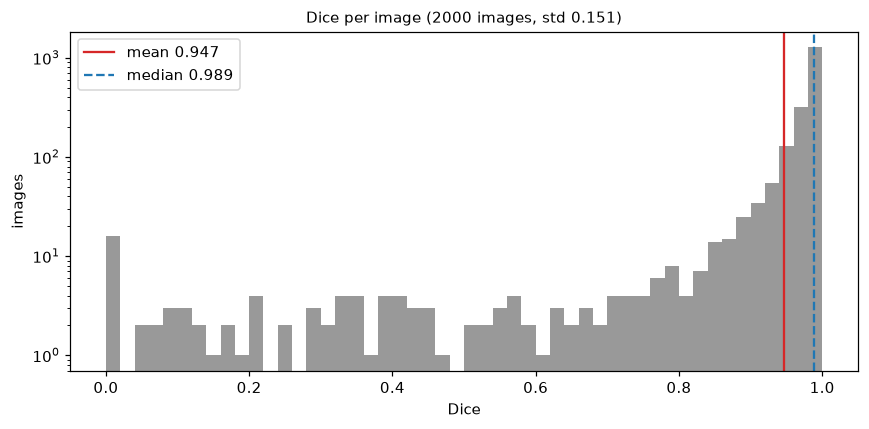

images          : 2000
mean Dice       : 0.9465
std             : 0.1515
median          : 0.9890
5th percentile  : 0.7413
minimum         : 0.0000
images >= 0.90  : 90.9%


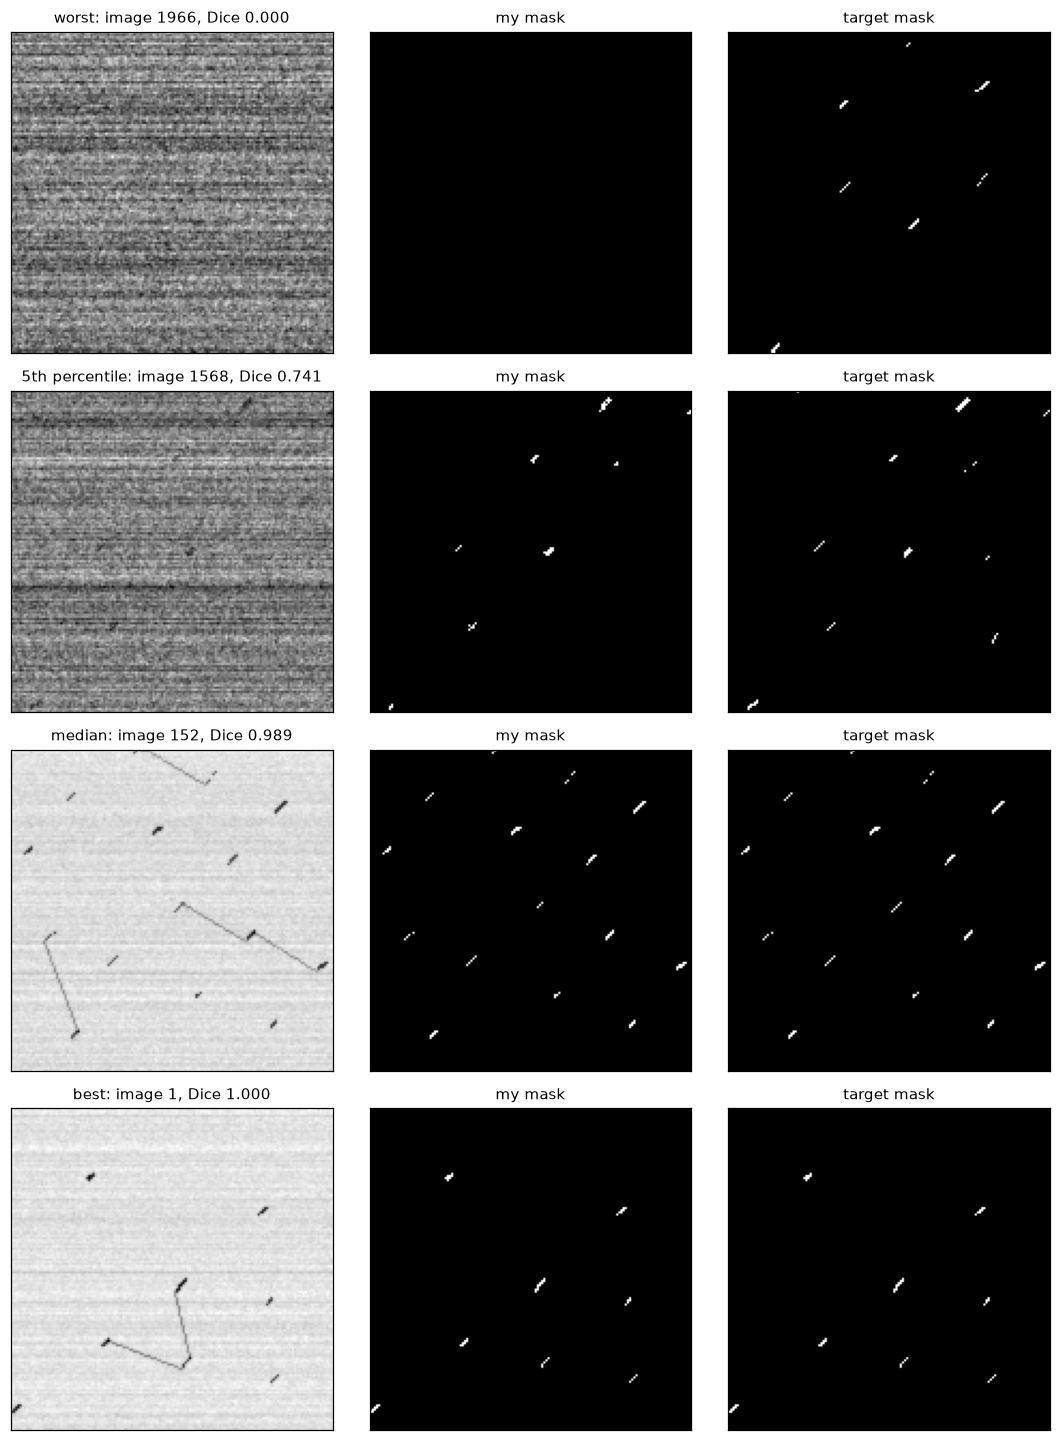

In [10]:
from csd import generate_dataset, load_dataset

results_dir = ROOT / "data" / "stage1_results"
if not (results_dir / "meta.json").exists():  # written last: absent if a run was interrupted
    generate_dataset(n=2000, out_dir=results_dir, seed=2026, overwrite=True)
scores = evaluate(results_dir)
ds = load_dataset(results_dir)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(scores, bins=np.linspace(0, 1, 51), color="0.6")
ax.axvline(scores.mean(), color="tab:red", label=f"mean {scores.mean():.3f}")
ax.axvline(np.median(scores), color="tab:blue", ls="--", label=f"median {np.median(scores):.3f}")
ax.set(
    xlabel="Dice",
    ylabel="images",
    yscale="log",
    title=f"Dice per image ({len(scores)} images, std {scores.std():.3f})",
)
ax.legend()
plt.tight_layout()
plt.show()

print(f"images          : {len(scores)}")
print(f"mean Dice       : {scores.mean():.4f}")
print(f"std             : {scores.std():.4f}")
print(f"median          : {np.median(scores):.4f}")
print(f"5th percentile  : {np.percentile(scores, 5):.4f}")
print(f"minimum         : {scores.min():.4f}")
print(f"images >= 0.90  : {np.mean(scores >= 0.90):.1%}")

order = np.argsort(scores)
picks = {
    "worst": order[0],
    "5th percentile": order[int(0.05 * len(order))],
    "median": order[len(order) // 2],
    "best": order[-1],
}
fig, axes = plt.subplots(len(picks), 3, figsize=(10, 3.3 * len(picks)))
for row, (name, k) in zip(axes, picks.items()):
    img = np.asarray(ds["images"][k], float)
    panel(row[0], img, f"{name}: image {k}, Dice {scores[k]:.3f}")
    panel(row[1], predict(img) > 0, "my mask")
    panel(row[2], np.asarray(ds["masks"][k]) > 0, "target mask")
plt.tight_layout()

## 9. Limitations

- The stick direction (45°) is assumed: the matched filter and the orientation filter are built
  on it, so a device whose sticks run in another direction needs `STICK_THETA` and the diagonal
  kernel changed.
- A stick shallower than `k_line` after the 5-px average gives no seed and is missed; one
  shorter than 5 px gains less from the average.
- The six parameters were tuned on simulated images only.